# MAC F244: Stochastic Calculus & Application to Finance
## Algorithmic Trading with Mean-Reverting Processes (OU and CIR)

This notebook implements the simulations, model calibration, and backtesting:
1. Ornstein-Uhlenbeck (OU) pairs trading on GOOGL / GOOG
2. Cox-Ingersoll-Ross (CIR) yield strategy on 10-Year Treasuries (^TNX) and bond ETFs (IEF / SHY)

Data split: 2019–2022 (in-sample calibration, ~70%) and 2023–2024 (out-of-sample backtesting, ~30%).

In [2]:
# Setup and imports
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from src import (
    CIRParams,
    CIRTradingConfig,
    OUParams,
    OUTradingConfig,
    calibrate_cir_wls,
    calibrate_ou_ols,
    evaluate_backtest,
    fetch_market_data,
    ou_analytical_moments,
    run_cir_yield_strategy,
    run_ou_pairs_strategy,
    simulate_cir_exact,
    simulate_ou_exact,
    test_pair_cointegration,
)

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

---
## 1. SDE Simulation (OU and CIR)

* **Ornstein–Uhlenbeck (OU):**
  $$dX_t = \theta(\mu - X_t)\,dt + \sigma\,dW_t$$
* **Cox–Ingersoll–Ross (CIR):**
  $$dr_t = \kappa(\theta - r_t)\,dt + \xi\sqrt{r_t}\,dW_t$$
  Feller condition for strict positivity ($r_t > 0$): $2\kappa\theta > \xi^2$.

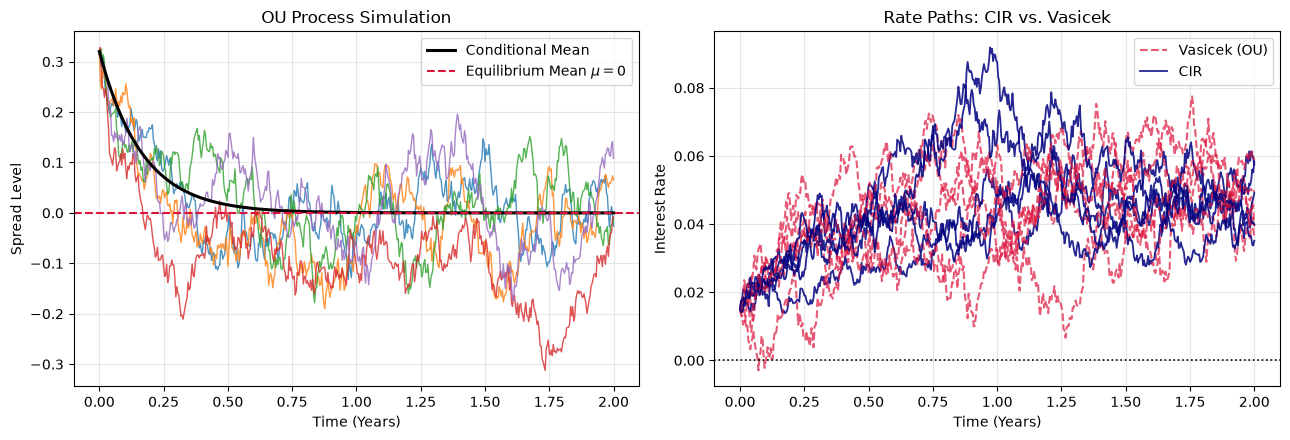

In [3]:
# Simulate OU paths using exact Gaussian transition law
ou_p = OUParams(theta=6.0, mu=0.0, sigma=0.28)
t_ou, paths_ou = simulate_ou_exact(ou_p, x0=0.32, T=2.0, dt=1/252, n_paths=5, seed=42)
moments_ou = ou_analytical_moments(ou_p, x0=0.32, t=t_ou)

# Simulate CIR and Vasicek (OU) paths from a low initial rate
cir_sat = CIRParams(kappa=3.5, theta=0.045, xi=0.15)
vas_p = OUParams(theta=3.5, mu=0.045, sigma=0.04)

_, paths_cir = simulate_cir_exact(cir_sat, r0=0.015, T=2.0, dt=1/252, n_paths=5, seed=88)
_, paths_vas = simulate_ou_exact(vas_p, x0=0.015, T=2.0, dt=1/252, n_paths=5, seed=88)

# Plot simulation comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) OU sample paths
for i in range(paths_ou.shape[0]):
    axes[0].plot(t_ou, paths_ou[i], lw=1.0, alpha=0.8)
axes[0].plot(t_ou, moments_ou["mean"], color="black", lw=2.2, label="Conditional Mean")
axes[0].axhline(0.0, color="crimson", ls="--", label=r"Equilibrium Mean $\mu=0$")
axes[0].set_title("OU Process Simulation")
axes[0].set_xlabel("Time (Years)")
axes[0].set_ylabel("Spread Level")
axes[0].legend()

# (b) Rate paths comparison: CIR vs Vasicek
for i in range(5):
    axes[1].plot(t_ou, paths_vas[i], color="crimson", ls="--", alpha=0.7, label="Vasicek (OU)" if i == 0 else None)
    axes[1].plot(t_ou, paths_cir[i], color="navy", lw=1.3, alpha=0.85, label="CIR" if i == 0 else None)
axes[1].axhline(0.0, color="black", lw=1.2, ls=":")
axes[1].set_title("Rate Paths: CIR vs. Vasicek")
axes[1].set_xlabel("Time (Years)")
axes[1].set_ylabel("Interest Rate")
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 2. Data Loading and Cointegration Test (GOOGL / GOOG)

Engle-Granger cointegration regression on log-prices:
$$\ln(\text{GOOGL}_t) = \alpha + \beta \ln(\text{GOOG}_t) + \varepsilon_t$$
followed by the Augmented Dickey-Fuller (ADF) test on residuals $\varepsilon_t$.

In [4]:
# Fetch daily price data and split into training and testing windows
DATA_DIR = Path("data")
tickers = ["GOOGL", "GOOG", "IEF", "SHY", "^TNX"]
bundle = fetch_market_data(
    tickers=tickers,
    start="2019-01-01",
    end="2025-01-01",
    cache_path=DATA_DIR / "market_prices_goog.csv",
    db_path=DATA_DIR / "market_data_goog.db",
)

eval_idx = bundle.prices.index.get_loc(bundle.prices.loc["2023-01-01":].index[0])
print(f"Total days: {bundle.n_trading_days} ({bundle.start_date} to {bundle.end_date})")
print(f"Training set (2019-2022): {eval_idx} days ({eval_idx/bundle.n_trading_days:.1%})")
print(f"Testing set  (2023-2024): {bundle.n_trading_days - eval_idx} days ({(bundle.n_trading_days - eval_idx)/bundle.n_trading_days:.1%})")

# Run Engle-Granger cointegration test on in-sample training data
coint_res = test_pair_cointegration(bundle.prices["GOOGL"].iloc[:eval_idx], bundle.prices["GOOG"].iloc[:eval_idx])
print("\n--- Engle-Granger Cointegration (GOOGL / GOOG, 2019-2022) ---")
print(f"Hedge Ratio (beta): {coint_res['beta']:.4f}")
print(f"R-squared:          {coint_res['r_squared']:.4f}")
print(f"ADF t-stat:         {coint_res['adf_tstat']:.4f}")
print(f"ADF p-value:        {coint_res['adf_pvalue']:.4e}")

Total days: 1510 (2019-01-02 to 2024-12-31)
Training set (2019-2022): 1008 days (66.8%)
Testing set  (2023-2024): 502 days (33.2%)

--- Engle-Granger Cointegration (GOOGL / GOOG, 2019-2022) ---
Hedge Ratio (beta): 0.9879
R-squared:          0.9996
ADF t-stat:         -3.4900
ADF p-value:        8.2473e-03


---
## 3. Model Calibration

* **OU Process:** Discrete AR(1) OLS regression:
  $$X_t = \alpha + \phi X_{t-1} + \varepsilon_t$$
  $$\theta = -\frac{\ln(\phi)}{\Delta t}, \quad \mu = \frac{\alpha}{1 - \phi}, \quad \sigma = \sigma_\varepsilon \sqrt{\frac{2\theta}{1 - \phi^2}}$$

* **CIR Process:** Weighted Least Squares (WLS) regression:
  $$\frac{r_t - r_{t-1}}{\sqrt{r_{t-1}}} = \frac{\kappa\theta\Delta t}{\sqrt{r_{t-1}}} - \kappa\Delta t\sqrt{r_{t-1}} + \xi\sqrt{\Delta t}\varepsilon_t$$

In [5]:
# Construct spread and calibrate OU parameters via AR(1) OLS
dt = 1.0 / 252.0
spread_train = (
    np.log(bundle.prices["GOOGL"].iloc[:eval_idx])
    - (coint_res["alpha"] + coint_res["beta"] * np.log(bundle.prices["GOOG"].iloc[:eval_idx]))
)

ou_cal = calibrate_ou_ols(spread_train.to_numpy(), dt=dt)

# Calibrate CIR parameters on 10Y yields via WLS
tnx_train = np.maximum(bundle.prices["^TNX"].iloc[:eval_idx].to_numpy() / 100.0, 1e-4)
cir_cal = calibrate_cir_wls(tnx_train, dt=dt)

cal_df = pd.DataFrame([
    {
        "Model / Asset": "OU (GOOGL/GOOG)",
        "Method": ou_cal.method,
        "Mean Reversion (theta / kappa)": round(ou_cal.params.theta, 3),
        "Equilibrium (mu / theta_CIR)": round(ou_cal.params.mu, 4),
        "Volatility (sigma / xi)": round(ou_cal.params.sigma, 4),
        "Half-Life (Days)": round(ou_cal.params.half_life * 252, 1),
        "Diagnostic": f"R^2 = {ou_cal.r_squared:.4f}",
    },
    {
        "Model / Asset": "CIR (10Y Yield ^TNX)",
        "Method": cir_cal.method,
        "Mean Reversion (theta / kappa)": round(cir_cal.params.kappa, 3),
        "Equilibrium (mu / theta_CIR)": round(cir_cal.params.theta, 4),
        "Volatility (sigma / xi)": round(cir_cal.params.xi, 4),
        "Half-Life (Days)": round(cir_cal.params.half_life * 252, 1),
        "Diagnostic": f"Feller = {cir_cal.feller_ratio:.2f} (>1)",
    },
])
display(cal_df)

,Model / Asset,Method,Mean Reversion (theta / kappa),Equilibrium (mu / theta_CIR),Volatility (sigma / xi),Half-Life (Days),Diagnostic
0,OU (GOOGL/GOOG),AR(1) OLS Regression,13.000,-0.0001,0.0331,13.4,R^2 = 0.9025
1,CIR (10Y Yield ^TNX),Weighted Least Squares (WLS),0.373,0.0267,0.0733,468.7,Feller = 3.71 (>1)


---
## 4. OU Pairs Trading Strategy (GOOGL / GOOG)

Out-of-sample backtest (2023–2024, $N=502$ days) with:
- Entry threshold: $z = \pm 1.25$
- Exit threshold: $z = \pm 0.20$
- Stop-loss threshold: $z = \pm 3.0$
- Transaction costs: 5 bps, execution lag: $T+1$

,Strategy,Total Return (%),Ann. Vol (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%),Hit Rate (%),Profit Factor
0,OU Pairs (GOOGL/GOOG),2.49,1.49,0.83,1.21,-1.36,94.44,39.17
1,Buy & Hold GOOGL,113.18,29.19,1.45,2.17,-22.14,56.80,1.29


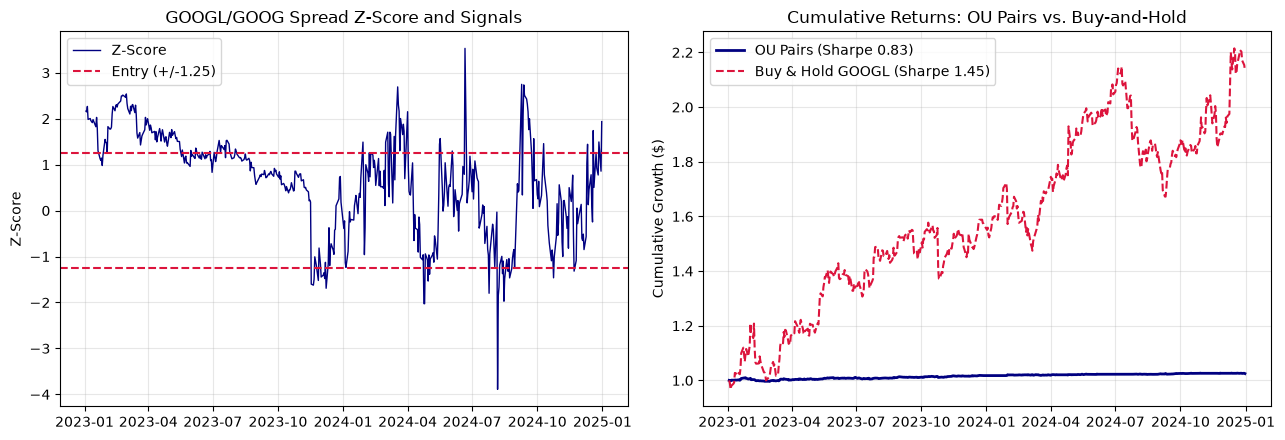

In [6]:
# Backtest OU pairs trading strategy on test set (2023-2024)
ou_cfg = OUTradingConfig(
    z_entry=1.25, z_exit=0.20, z_stop=3.0, lookback=120,
    recalib_step=5, max_half_life_days=45.0, gross_leverage=1.5,
    tc_bps=5.0, borrow_bps_annual=25.0, execution_lag=1,
)
bt_ou, diag_ou = run_ou_pairs_strategy(
    bundle.prices["GOOGL"], bundle.prices["GOOG"], ou_cfg, start_eval_idx=eval_idx, name="OU Pairs (GOOGL/GOOG)"
)

# Buy-and-hold benchmark on GOOGL
googl_rets = pd.DataFrame({"GOOGL": bundle.prices["GOOGL"].pct_change().fillna(0.0).iloc[eval_idx:]})
googl_w = pd.DataFrame({"GOOGL": 1.0}, index=googl_rets.index)
bt_googl_bh = evaluate_backtest(
    "Buy & Hold GOOGL", googl_rets, googl_w, pd.Series(1.0, index=googl_rets.index),
    tc_bps=0.0, borrow_bps_annual=0.0, execution_lag=1,
)

p1_df = pd.DataFrame([
    {"Strategy": bt_ou.name, **{k: round(v, 2) for k, v in bt_ou.metrics.to_dict().items()}},
    {"Strategy": bt_googl_bh.name, **{k: round(v, 2) for k, v in bt_googl_bh.metrics.to_dict().items()}},
])
display(p1_df[["Strategy", "Total Return (%)", "Ann. Vol (%)", "Sharpe Ratio", "Sortino Ratio", "Max Drawdown (%)", "Hit Rate (%)", "Profit Factor"]])

# Plot Z-score and cumulative returns
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(diag_ou.index, diag_ou["z_score"], color="navy", lw=1.0, label="Z-Score")
axes[0].axhline(ou_cfg.z_entry, color="crimson", ls="--", label="Entry (+/-1.25)")
axes[0].axhline(-ou_cfg.z_entry, color="crimson", ls="--")
axes[0].set_title("GOOGL/GOOG Spread Z-Score and Signals")
axes[0].set_ylabel("Z-Score")
axes[0].legend()

axes[1].plot((1 + bt_ou.net_returns).cumprod(), color="navy", lw=2.0, label=f"OU Pairs (Sharpe {bt_ou.metrics.sharpe_ratio:.2f})")
axes[1].plot((1 + bt_googl_bh.net_returns).cumprod(), color="crimson", ls="--", label=f"Buy & Hold GOOGL (Sharpe {bt_googl_bh.metrics.sharpe_ratio:.2f})")
axes[1].set_title("Cumulative Returns: OU Pairs vs. Buy-and-Hold")
axes[1].set_ylabel("Cumulative Growth ($)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Levered Performance (5x Leverage)

In [14]:
# Compute performance metrics under 5x leverage
lev = 5.0
levered_ret = lev * bt_ou.net_returns
levered_cum = (1 + levered_ret).cumprod()
levered_vol = levered_ret.std() * np.sqrt(252) * 100
levered_dd = ((levered_cum / levered_cum.cummax()) - 1).min() * 100

print(f"5x Levered OU Pairs: Return = {(levered_cum.iloc[-1]-1)*100:.2f}%, Vol = {levered_vol:.2f}%, Max Drawdown = {levered_dd:.2f}%")
print(f"Buy & Hold GOOGL:     Return = {bt_googl_bh.metrics.total_return*100:.2f}%, Vol = {bt_googl_bh.metrics.annual_vol*100:.2f}%, Max Drawdown = {bt_googl_bh.metrics.max_drawdown*100:.2f}%")

5x Levered OU Pairs: Return = 12.58%, Vol = 7.46%, Max Drawdown = -6.67%
Buy & Hold GOOGL:     Return = 113.18%, Vol = 29.19%, Max Drawdown = -22.14%


---
## 5. CIR Dynamic Yield Strategy (^TNX / IEF / SHY)

Dynamic duration allocation between 7-10 Year Treasuries (IEF) and 1-3 Year Treasuries (SHY) based on CIR yield deviations.

,Strategy,Total Return (%),Ann. Vol (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%),Hit Rate (%),Profit Factor
0,CIR Dynamic (IEF/SHY),2.48,5.52,0.25,0.37,-9.01,53.85,1.34
1,Buy & Hold IEF,2.19,8.14,0.17,0.25,-10.16,50.20,1.03


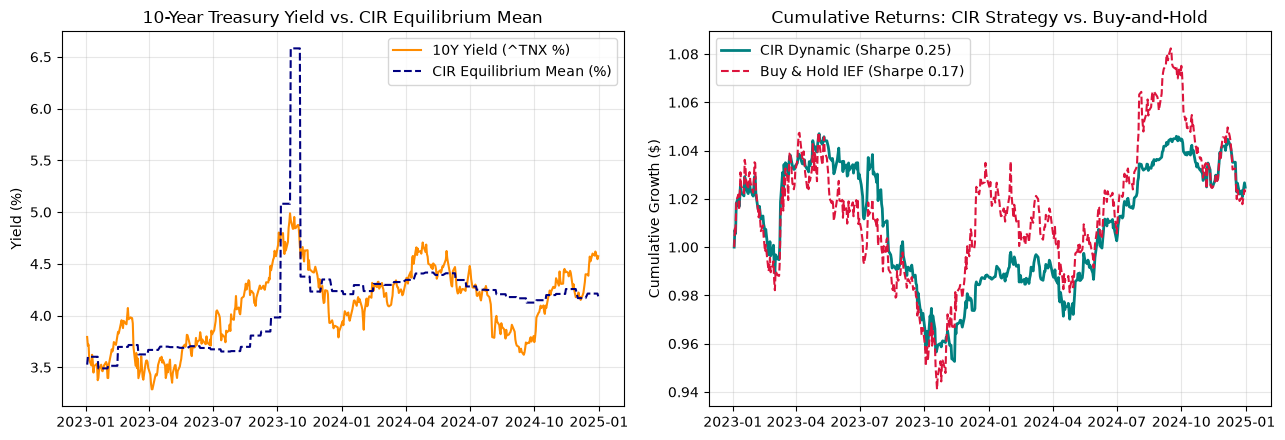

In [8]:
# Backtest CIR dynamic yield strategy
cir_cfg = CIRTradingConfig(
    z_entry=0.75, z_exit=0.10, z_stop=2.5, vol_stress_mult=1.15,
    lookback=180, recalib_step=10, tc_bps=3.0, borrow_bps_annual=0.0, execution_lag=1,
)
bt_cir, diag_cir = run_cir_yield_strategy(
    bundle.prices["^TNX"], bundle.prices["IEF"], bundle.prices["SHY"],
    cir_cfg, start_eval_idx=eval_idx, name="CIR Dynamic (IEF/SHY)"
)

# Buy-and-hold benchmark on IEF
ief_rets = pd.DataFrame({"IEF": bundle.prices["IEF"].pct_change().fillna(0.0).iloc[eval_idx:]})
ief_w = pd.DataFrame({"IEF": 1.0}, index=ief_rets.index)
bt_ief_bh = evaluate_backtest(
    "Buy & Hold IEF", ief_rets, ief_w, pd.Series(1.0, index=ief_rets.index),
    tc_bps=0.0, borrow_bps_annual=0.0, execution_lag=1,
)

p2_df = pd.DataFrame([
    {"Strategy": bt_cir.name, **{k: round(v, 2) for k, v in bt_cir.metrics.to_dict().items()}},
    {"Strategy": bt_ief_bh.name, **{k: round(v, 2) for k, v in bt_ief_bh.metrics.to_dict().items()}},
])
display(p2_df[["Strategy", "Total Return (%)", "Ann. Vol (%)", "Sharpe Ratio", "Sortino Ratio", "Max Drawdown (%)", "Hit Rate (%)", "Profit Factor"]])

# Plot yields and cumulative returns
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(diag_cir.index, diag_cir["rate_decimal"] * 100, color="darkorange", label="10Y Yield (^TNX %)")
axes[0].plot(diag_cir.index, diag_cir["theta"] * 100, color="navy", ls="--", label="CIR Equilibrium Mean (%)")
axes[0].set_title("10-Year Treasury Yield vs. CIR Equilibrium Mean")
axes[0].set_ylabel("Yield (%)")
axes[0].legend()

axes[1].plot((1 + bt_cir.net_returns).cumprod(), color="teal", lw=2.0, label="CIR Dynamic (Sharpe 0.25)")
axes[1].plot((1 + bt_ief_bh.net_returns).cumprod(), color="crimson", ls="--", label="Buy & Hold IEF (Sharpe 0.17)")
axes[1].set_title("Cumulative Returns: CIR Strategy vs. Buy-and-Hold")
axes[1].set_ylabel("Cumulative Growth ($)")
axes[1].legend()
plt.tight_layout()
plt.show()